In [9]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import pickle

In [2]:
IMG_SIZE = 224
BATCH_SIZE = 32
N_CLASSES = 6
EPOCHS = 20

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/kaggle/input/datasets/shlyapa88man/synthetic-pipe-dataset/pipe_dataset/train',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    '/kaggle/input/datasets/shlyapa88man/synthetic-pipe-dataset/pipe_dataset/val',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

print("\nИндексы классов:", train_generator.class_indices)

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

x = base_model.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.2)(x)
predictions = layers.Dense(N_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Found 900 images belonging to 6 classes.
Found 132 images belonging to 6 classes.

Индексы классов: {'asbestos': 0, 'ceramics': 1, 'concrete': 2, 'geotextile': 3, 'hdp': 4, 'metal': 5}


I0000 00:00:1793217594.664702      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793217594.668671      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,430,598 (9.27 MB)

 Trainable params: 172,614 (674.27 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [3]:
history_initial = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    validation_data=val_generator,
    validation_steps=val_generator.samples // BATCH_SIZE,
    epochs=10,
    verbose=1
)

Epoch 1/10


2026-10-28 20:00:38.975473: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 20:00:39.113106: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793217641.944371     156 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


20/28 ━━━━━━━━━━━━━━━━━━━━ 29s 4s/step - accuracy: 0.5550 - loss: 1.2710

2026-10-28 20:02:01.650790: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 20:02:01.812739: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 20:02:01.950911: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


28/28 ━━━━━━━━━━━━━━━━━━━━ 150s 5s/step - accuracy: 0.7512 - loss: 0.6961 - val_accuracy: 0.8750 - val_loss: 0.2021
Epoch 2/10
 1/28 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7188 - loss: 0.4026

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.7188 - loss: 0.4026 - val_accuracy: 0.9609 - val_loss: 0.1825
Epoch 3/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 446ms/step - accuracy: 0.8721 - loss: 0.2642 - val_accuracy: 0.8438 - val_loss: 0.2059
Epoch 4/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8750 - loss: 0.2762 - val_accuracy: 0.8594 - val_loss: 0.2018
Epoch 5/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 12s 440ms/step - accuracy: 0.8963 - loss: 0.2210 - val_accuracy: 0.9531 - val_loss: 0.1376
Epoch 6/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8750 - loss: 0.2103 - val_accuracy: 0.9766 - val_loss: 0.1329
Epoch 7/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 455ms/step - accuracy: 0.9241 - loss: 0.1695 - val_accuracy: 0.9688 - val_loss: 0.0885
Epoch 8/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.1025 - val_accuracy: 0.9844 - val_loss: 0.0866
Epoch 9/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 444ms/step - accuracy: 0.9217 - loss: 0.1700 - val_accuracy: 0.9922 - val_

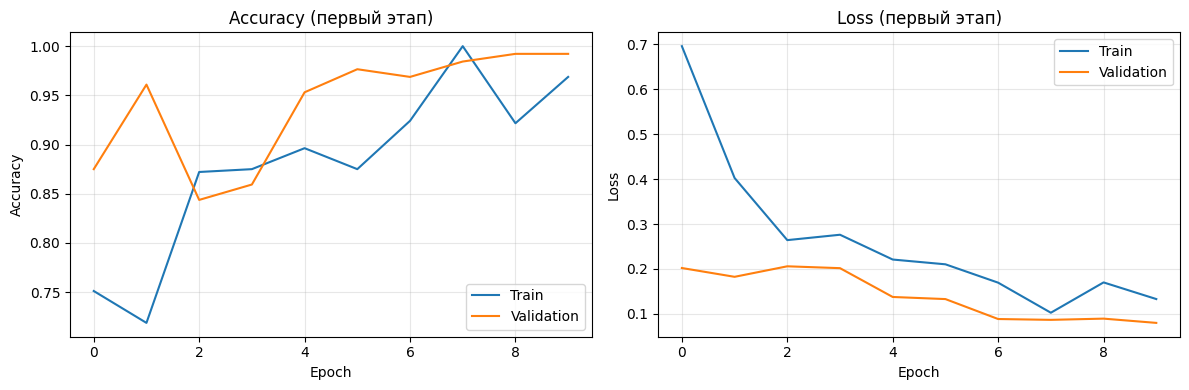

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_initial.history['accuracy'], label='Train')
axes[0].plot(history_initial.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy (первый этап)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_initial.history['loss'], label='Train')
axes[1].plot(history_initial.history['val_loss'], label='Validation')
axes[1].set_title('Loss (первый этап)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/training_stage1.png', dpi=150)
plt.show()

In [7]:
base_model.trainable = True

for layer in base_model.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
    tf.keras.callbacks.ModelCheckpoint('/kaggle/working/pipe_model_best.keras', save_best_only=True)
]

history_finetune = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    validation_data=val_generator,
    validation_steps=val_generator.samples // BATCH_SIZE,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

history = {
    'accuracy': history_initial.history['accuracy'] + history_finetune.history['accuracy'],
    'val_accuracy': history_initial.history['val_accuracy'] + history_finetune.history['val_accuracy'],
    'loss': history_initial.history['loss'] + history_finetune.history['loss'],
    'val_loss': history_initial.history['val_loss'] + history_finetune.history['val_loss']
}

Epoch 1/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 46s 968ms/step - accuracy: 0.9793 - loss: 0.0553 - val_accuracy: 0.8516 - val_loss: 0.7922 - learning_rate: 1.0000e-04
Epoch 2/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9688 - loss: 0.1839 - val_accuracy: 0.8438 - val_loss: 0.8108 - learning_rate: 1.0000e-04
Epoch 3/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 12s 435ms/step - accuracy: 0.9896 - loss: 0.0431 - val_accuracy: 0.8359 - val_loss: 1.4278 - learning_rate: 1.0000e-04
Epoch 4/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9688 - loss: 0.0706 - val_accuracy: 0.8438 - val_loss: 1.3435 - learning_rate: 1.0000e-04
Epoch 5/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 446ms/step - accuracy: 0.9850 - loss: 0.0390 - val_accuracy: 0.8359 - val_loss: 1.2015 - learning_rate: 5.0000e-05
Epoch 6/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 1.0000 - loss: 0.0049 - val_accuracy: 0.8281 - val_loss: 1.2483 - learning_rate: 5.0000e-05


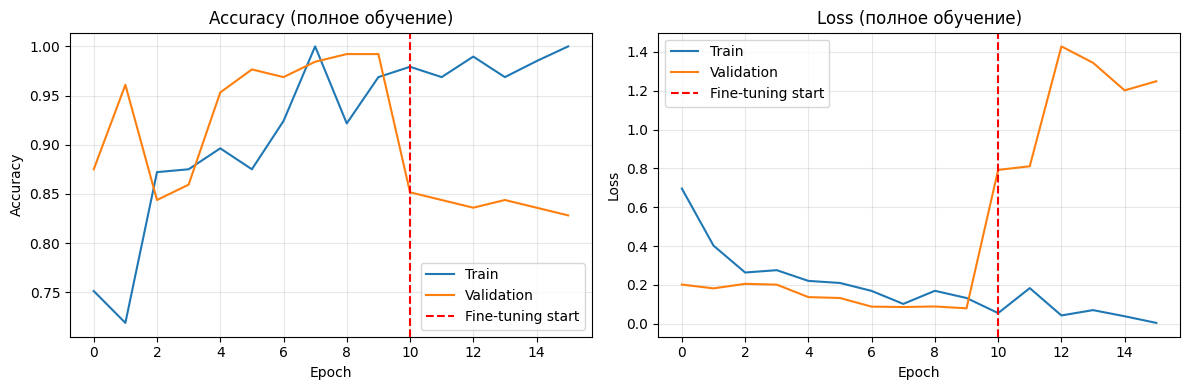

Модель сохранена: pipe_model_final.keras


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['accuracy'], label='Train')
axes[0].plot(history['val_accuracy'], label='Validation')
axes[0].axvline(x=len(history_initial.history['accuracy']), color='r', linestyle='--', label='Fine-tuning start')
axes[0].set_title('Accuracy (полное обучение)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['loss'], label='Train')
axes[1].plot(history['val_loss'], label='Validation')
axes[1].axvline(x=len(history_initial.history['accuracy']), color='r', linestyle='--', label='Fine-tuning start')
axes[1].set_title('Loss (полное обучение)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/training_complete.png', dpi=150)
plt.show()

model.save('/kaggle/working/pipe_model_final.keras')
print("Модель сохранена: pipe_model_final.keras")

with open('/kaggle/working/labels.txt', 'w') as f:
    for class_name in train_generator.class_indices:
        f.write(f"{class_name}\n")

In [11]:
with open('/kaggle/working/training_history.pkl', 'wb') as f:
    pickle.dump({
        'history_finetune': history_finetune,
        'history_initial': history_initial,
        'final_accuracy': history_finetune.history['val_accuracy'][-1],
        'final_loss': history_finetune.history['val_loss'][-1]
    }, f)
print("История обучения сохранена в pipe_model_saved/training_history.pkl")

История обучения сохранена в pipe_model_saved/training_history.pkl
